## ***Climate Data Cleaning***

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

PATH = "../Data/Raw Data/egypt_all_governorates climate_1995_2026.csv"
df = pd.read_csv(PATH)
df.head()

,Governorate,Year,Month,T2M,T2M_MAX,T2M_MIN,T2M_RANGE,TS,PRECTOTCORR,RH2M,QV2M,PW,ALLSKY_SFC_SW_DWN,CLRSKY_SFC_SW_DWN,ALLSKY_SFC_LW_DWN,WS2M,WD2M,WS10M,PS
0,Cairo,1995,1,11.43,21.41,0.92,12.44,11.29,0.04,64.60,5.26,-999.0,12.93,14.17,26.20,2.00,318.8,3.07,100.49
1,Cairo,1995,2,13.60,26.23,3.46,12.84,14.04,0.29,63.14,5.75,-999.0,15.22,17.40,27.23,2.53,342.9,3.76,100.16
2,Cairo,1995,3,16.89,31.16,5.74,15.09,17.99,0.09,51.83,5.53,-999.0,19.88,21.32,27.81,2.44,355.2,3.57,100.01
3,Cairo,1995,4,19.26,36.44,7.19,16.80,20.84,0.02,45.67,5.49,-999.0,22.33,24.59,29.73,3.41,13.7,4.72,99.74
4,Cairo,1995,5,24.17,41.88,10.92,18.24,26.49,0.00,42.31,6.74,-999.0,27.31,27.80,31.42,3.35,1.6,4.52,99.72


In [3]:
print("Shape:", df.shape)
df.info()

Shape: (10314, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10314 entries, 0 to 10313
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Governorate        10314 non-null  object 
 1   Year               10314 non-null  int64  
 2   Month              10314 non-null  int64  
 3   T2M                10314 non-null  float64
 4   T2M_MAX            10314 non-null  float64
 5   T2M_MIN            10314 non-null  float64
 6   T2M_RANGE          10314 non-null  float64
 7   TS                 10314 non-null  float64
 8   PRECTOTCORR        10314 non-null  float64
 9   RH2M               10314 non-null  float64
 10  QV2M               10314 non-null  float64
 11  PW                 10314 non-null  float64
 12  ALLSKY_SFC_SW_DWN  10314 non-null  float64
 13  CLRSKY_SFC_SW_DWN  10314 non-null  float64
 14  ALLSKY_SFC_LW_DWN  10314 non-null  float64
 15  WS2M               10314 non-null  float64
 16  WD2

In [4]:
df = df.rename(columns={
    'T2M': 'Temp_Mean',                
    'T2M_MAX': 'Temp_Max',            
    'T2M_MIN': 'Temp_Min',            
    'T2M_RANGE': 'Temp_Range',        
    'TS': 'Surface_Temp',             
    'PRECTOTCORR': 'Precipitation',   
    'RH2M': 'Humidity_2m',            
    'QV2M': 'Specific_Humidity',      
    'PW': 'Precipitable_Water',       
    'ALLSKY_SFC_SW_DWN': 'Solar_Rad_AllSky',   
    'CLRSKY_SFC_SW_DWN': 'Solar_Rad_ClearSky', 
    'ALLSKY_SFC_LW_DWN': 'Thermal_Rad',        
    'WS2M': 'Wind_Speed_2m',          
    'WD2M': 'Wind_Direction_2m',      
    'WS10M': 'Wind_Speed_10m',        
    'PS': 'Surface_Pressure'})
print(df.columns)

Index(['Governorate', 'Year', 'Month', 'Temp_Mean', 'Temp_Max', 'Temp_Min',
       'Temp_Range', 'Surface_Temp', 'Precipitation', 'Humidity_2m',
       'Specific_Humidity', 'Precipitable_Water', 'Solar_Rad_AllSky',
       'Solar_Rad_ClearSky', 'Thermal_Rad', 'Wind_Speed_2m',
       'Wind_Direction_2m', 'Wind_Speed_10m', 'Surface_Pressure'],
      dtype='object')


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Year,10314.0,2010.418848,9.189129,1995.0,2002.00,2010.000,2018.0000,2026.00
Month,10314.0,6.473822,3.441994,1.0,3.00,6.000,9.0000,12.00
Temp_Mean,10314.0,19.931033,52.573384,-999.0,16.84,23.140,28.0800,36.56
Temp_Max,10314.0,32.297120,53.314631,-999.0,28.99,35.835,41.2800,49.30
Temp_Min,10314.0,10.827423,52.129015,-999.0,7.72,13.590,19.0975,27.74
Temp_Range,10314.0,10.130541,51.915563,-999.0,10.47,14.190,16.3800,20.27
Surface_Temp,10314.0,21.218085,52.722707,-999.0,17.73,24.485,30.0100,39.56
Precipitation,10314.0,-2.458986,51.058620,-999.0,0.00,0.000,0.1200,13.13
Humidity_2m,10314.0,47.525413,55.839501,-999.0,41.02,52.070,62.3075,86.14
Specific_Humidity,10314.0,5.325670,51.544351,-999.0,5.71,7.260,10.0500,19.04


In [6]:
print("عدد المحافظات:", df["Governorate"].nunique())
print("السنين:", df["Year"].min(), "->", df["Year"].max())
print()
print("عدد الصفوف لكل شهر:")
print(df["Month"].value_counts().sort_index())
print()
print("ايه الشهور الموجودة:", sorted(df["Month"].unique()))

عدد المحافظات: 27
السنين: 1995 -> 2026

عدد الصفوف لكل شهر:
Month
1     864
2     864
3     864
4     864
5     864
6     864
7     864
8     864
9     864
10    864
11    837
12    837
Name: count, dtype: int64

ايه الشهور الموجودة: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]


In [7]:
rows_per_gov = df.groupby("Governorate").size()
print(rows_per_gov.describe())
print("كل المحافظات متساوية؟", rows_per_gov.nunique() == 1)

count     27.0
mean     382.0
std        0.0
min      382.0
25%      382.0
50%      382.0
75%      382.0
max      382.0
dtype: float64
كل المحافظات متساوية؟ True


In [8]:
print("NaN حقيقية في الملف:", df.isna().sum().sum())

NaN حقيقية في الملف: 0


In [9]:
num_cols = [c for c in df.columns if c not in ("Governorate", "Year", "Month")]
df[num_cols].min().sort_values()

Temp_Mean            -999.0
Temp_Max             -999.0
Temp_Min             -999.0
Temp_Range           -999.0
Surface_Temp         -999.0
Precipitation        -999.0
Humidity_2m          -999.0
Specific_Humidity    -999.0
Precipitable_Water   -999.0
Solar_Rad_AllSky     -999.0
Solar_Rad_ClearSky   -999.0
Thermal_Rad          -999.0
Wind_Speed_2m        -999.0
Wind_Direction_2m    -999.0
Wind_Speed_10m       -999.0
Surface_Pressure     -999.0
dtype: float64

In [10]:
suspects = df[num_cols].min()
suspects = suspects[suspects < -100]
for c in suspects.index:
    print(c, "-->", sorted(df.loc[df[c] < -100, c].unique()))

Temp_Mean --> [np.float64(-999.0)]
Temp_Max --> [np.float64(-999.0)]
Temp_Min --> [np.float64(-999.0)]
Temp_Range --> [np.float64(-999.0)]
Surface_Temp --> [np.float64(-999.0)]
Precipitation --> [np.float64(-999.0)]
Humidity_2m --> [np.float64(-999.0)]
Specific_Humidity --> [np.float64(-999.0)]
Precipitable_Water --> [np.float64(-999.0)]
Solar_Rad_AllSky --> [np.float64(-999.0)]
Solar_Rad_ClearSky --> [np.float64(-999.0)]
Thermal_Rad --> [np.float64(-999.0)]
Wind_Speed_2m --> [np.float64(-999.0)]
Wind_Direction_2m --> [np.float64(-999.0)]
Wind_Speed_10m --> [np.float64(-999.0)]
Surface_Pressure --> [np.float64(-999.0)]


In [11]:
sentinel_counts = (df[num_cols] == -999).sum()
sentinel_pct = (sentinel_counts / len(df) * 100).round(2)
pd.DataFrame({"count": sentinel_counts, "pct": sentinel_pct}).sort_values("count", ascending=False)

,count,pct
Precipitable_Water,2052,19.90
Thermal_Rad,108,1.05
Solar_Rad_AllSky,108,1.05
Solar_Rad_ClearSky,108,1.05
Temp_Mean,27,0.26
Temp_Max,27,0.26
Temp_Min,27,0.26
Temp_Range,27,0.26
Specific_Humidity,27,0.26
Humidity_2m,27,0.26


In [12]:
bad = df[df["Temp_Mean"] == -999]
print(bad.groupby(["Year", "Month"]).size())

Year  Month
2026  10       27
dtype: int64


In [13]:
rest = df[~((df.Year == 2026) & (df.Month == 10))]

print("Precipitable_Water الناقص حسب السنة:")
print(rest[rest["Precipitable_Water"] == -999].groupby("Year").size())
print()
print("الإشعاع الناقص في 2026 حسب الشهر:")
print(df[(df.Year == 2026) & (df["Solar_Rad_AllSky"] == -999)].groupby("Month").size())

Precipitable_Water الناقص حسب السنة:
Year
1995    324
1996    324
1997    324
1998    324
1999    324
2000    324
2026     81
dtype: int64

الإشعاع الناقص في 2026 حسب الشهر:
Month
7     27
8     27
9     27
10    27
dtype: int64


In [14]:
df_clean = df.replace([-999, -9999], np.nan)
df_clean[num_cols].isna().sum()

Temp_Mean               27
Temp_Max                27
Temp_Min                27
Temp_Range              27
Surface_Temp            27
Precipitation           27
Humidity_2m             27
Specific_Humidity       27
Precipitable_Water    2052
Solar_Rad_AllSky       108
Solar_Rad_ClearSky     108
Thermal_Rad            108
Wind_Speed_2m           27
Wind_Direction_2m       27
Wind_Speed_10m          27
Surface_Pressure        27
dtype: int64

In [15]:
pw_ok = df_clean.dropna(subset=["Precipitable_Water"])
corr_pw = pw_ok[num_cols + ["Year"]].corr()["Precipitable_Water"].drop("Precipitable_Water").sort_values()
corr_pw.round(2)

Temp_Range           -0.12
Precipitation        -0.08
Wind_Speed_10m        0.00
Wind_Direction_2m     0.03
Year                  0.10
Wind_Speed_2m         0.10
Surface_Pressure      0.15
Humidity_2m           0.19
Solar_Rad_ClearSky    0.28
Solar_Rad_AllSky      0.28
Temp_Max              0.38
Temp_Mean             0.63
Surface_Temp          0.64
Temp_Min              0.75
Specific_Humidity     0.80
Thermal_Rad           0.87
Name: Precipitable_Water, dtype: float64

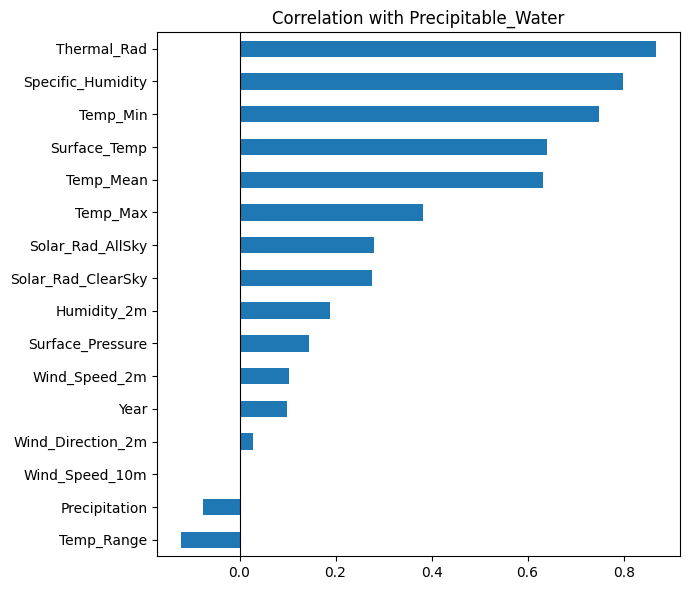

In [16]:
corr_pw.plot(kind="barh", figsize=(7, 6), title="Correlation with Precipitable_Water")
plt.axvline(0, color="k", lw=0.8)
plt.tight_layout()
plt.show()

In [17]:
diff = (df_clean["Temp_Range"] - (df_clean["Temp_Max"] - df_clean["Temp_Min"])).abs()
print(diff.describe().round(2))
df_clean.loc[(df_clean.Governorate == "Cairo") & (df_clean.Year == 1995) & (df_clean.Month == 1),
            ["Temp_Mean", "Temp_Max", "Temp_Min", "Temp_Range"]]

count    10287.00
mean         8.75
std          3.18
min          1.25
25%          6.34
50%          8.49
75%         10.83
max         22.20
dtype: float64


,Temp_Mean,Temp_Max,Temp_Min,Temp_Range
0,11.43,21.41,0.92,12.44


In [18]:
DROP_PW = True

df_clean = df_clean.dropna(subset=num_cols, how="all")

if DROP_PW:
    df_clean = df_clean.drop(columns=["Precipitable_Water"], errors="ignore")

MONTHS = {
    1: "January", 2: "February", 3: "March", 4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September", 10: "October", 11: "November", 12: "December"}
df_clean["Month"] = df_clean["Month"].map(MONTHS)

df_clean = df_clean.reset_index(drop=True)
print("Shape:", df_clean.shape)
df_clean.head()

Shape: (10287, 18)


,Governorate,Year,Month,Temp_Mean,Temp_Max,Temp_Min,Temp_Range,Surface_Temp,Precipitation,Humidity_2m,Specific_Humidity,Solar_Rad_AllSky,Solar_Rad_ClearSky,Thermal_Rad,Wind_Speed_2m,Wind_Direction_2m,Wind_Speed_10m,Surface_Pressure
0,Cairo,1995,January,11.43,21.41,0.92,12.44,11.29,0.04,64.60,5.26,12.93,14.17,26.20,2.00,318.8,3.07,100.49
1,Cairo,1995,February,13.60,26.23,3.46,12.84,14.04,0.29,63.14,5.75,15.22,17.40,27.23,2.53,342.9,3.76,100.16
2,Cairo,1995,March,16.89,31.16,5.74,15.09,17.99,0.09,51.83,5.53,19.88,21.32,27.81,2.44,355.2,3.57,100.01
3,Cairo,1995,April,19.26,36.44,7.19,16.80,20.84,0.02,45.67,5.49,22.33,24.59,29.73,3.41,13.7,4.72,99.74
4,Cairo,1995,May,24.17,41.88,10.92,18.24,26.49,0.00,42.31,6.74,27.31,27.80,31.42,3.35,1.6,4.52,99.72


In [19]:
# مفيش تكرار
assert not df_clean.duplicated(["Governorate", "Year", "Month"]).any()
# MAX >= MIN
assert (df_clean["Temp_Max"] >= df_clean["Temp_Min"]).all()
# الرطوبة 0-100
assert df_clean["Humidity_2m"].between(0, 100).all()
# اتجاه الرياح 0-360
assert df_clean["Wind_Direction_2m"].between(0, 360).all()
# مفيش شهور مش متحولة
assert df_clean["Month"].notna().all()
# مفيش -999 متبقية
assert not (df_clean.select_dtypes("number") <= -900).any().any()
print("كل الـ checks عدت")

كل الـ checks عدت


In [20]:
print("المتبقي من NaN:")
df_clean.isna().sum()[lambda s: s > 0]

المتبقي من NaN:


Solar_Rad_AllSky      81
Solar_Rad_ClearSky    81
Thermal_Rad           81
dtype: int64

In [21]:
solar_cols = ['Solar_Rad_AllSky', 'Solar_Rad_ClearSky', 'Thermal_Rad']
for col in solar_cols:
    df_clean[col] = df_clean.groupby(['Governorate', 'Month'])[col].transform(lambda x: x.fillna(x.mean()))
print("عدد الـ NaN المتبقية:", df_clean[solar_cols].isna().sum())

عدد الـ NaN المتبقية: Solar_Rad_AllSky      0
Solar_Rad_ClearSky    0
Thermal_Rad           0
dtype: int64


In [22]:
climate_gov_mapping = {
    'Assiut': 'Asyut',
    'Gharbia': 'Gharbiya',
    'Matrouh': 'Marsa Matrouh',
    'Menofia': 'Monufia',
    'Qaliubiya': 'Qalyoubia',
    'Sharqia': 'Sharqiya',
    'Beni Suef': 'Bani Suef',
    'New Valley': 'New Valley'}

df_clean['Governorate'] = df_clean['Governorate'].replace(climate_gov_mapping)
df_clean['Governorate'] = df_clean['Governorate'].str.strip().str.title()

In [24]:
df_clean.to_csv("../Data/Clean Data/egypt_climate_clean.csv", index=False)